(GM24-data)=
# Geng & Mohn 2024 data

This notebook plots Geng, M., & Mohn, C. E. (2024). Ab initio constraints on the melting of silica at high pressures up to 500 GPa. Physical Review B, 109(2), 024106. https://doi.org/10.1103/PhysRevB.109.024106

Original data requested for Figure 2 not included in the original paper.

## Notes

* Figure 1 lines do not match the text. The author says the fit in text are correct. Aug 2025.
* Figure 2 liquidus densities are a bit above the liquidus temperature. Author confirms they are not exactly on the liquidus. Aug 2025.

Updated 10/13/2025 sts

In [14]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data # defines gm24mc object with 2-phase fit recommended by authors
%run -i scripts/define_mc 
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'DFT-GM-'


In GM24 Fig 1, the two-phase equation does not match what is plotted in the figure.
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
1sigma =  200.0


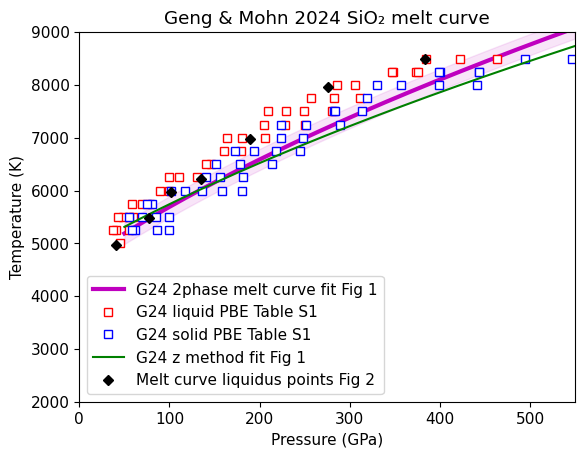

In [34]:
print('In GM24 Fig 1, the two-phase equation does not match what is plotted in the figure.')

# Geng Mohn melt curve
plt.plot(gm24mc.P,gm24mc.T,'m-',linewidth=3,label='G24 2phase melt curve fit Fig 1')

terr=600/3 # 3 sigma is about 500 K from author email
print('1sigma = ',terr)
plt.fill_between(gm24mc.P,gm24mc.T-terr,gm24mc.T+terr,alpha=0.1,color='m')


#plt.plot(gm24mc.P,gm24mc.T+terr,'m:')
#plt.plot(gm24mc.P,gm24mc.T-terr,'m:')
if 1:
    plt.plot(eosdat_list[G24mcl['id']].P_liquid,eosdat_list[G24mcl['id']].T_liquid,'s',color='red',mfc='white',label=G24mcl['lab']+' Table S1')
    plt.plot(eosdat_list[G24mcs['id']].P_solid,eosdat_list[G24mcs['id']].T_solid,'s',color='blue',mfc='white',label=G24mcs['lab']+' Table S1')

plt.plot(gm24mcz.P,gm24mcz.T,'-',color='green',label='G24 z method fit Fig 1')
plt.plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].T_liquid,'D',color='k',markersize=5,label='Melt curve liquidus points Fig 2')

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Geng & Mohn 2024 SiO₂ melt curve')
plt.legend()
plt.xlim(0,550)
plt.ylim(2000,9000)
plt.show()

## Original Figure 1 from Geng & Mohn 2024

See [https://journals.aps.org/prb/abstract/10.1103/PhysRevB.109.024106](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.109.024106).


<img src="./figs/GM24-Fig1.png" alt="Figure 1 from Geng & Mohn 2024" width=800 />

In GM24 Fig 1, the two-phase equation does not match what is plotted in the figure.


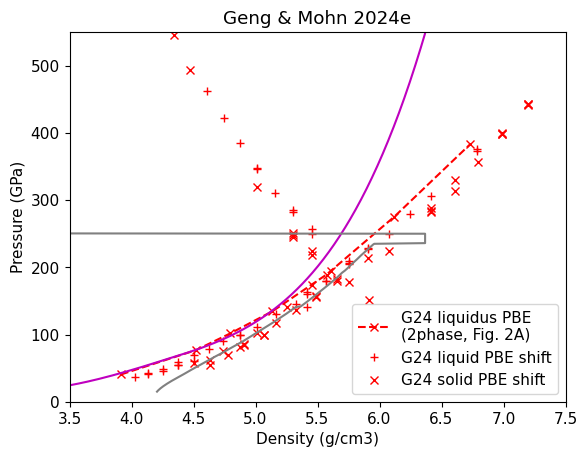

In [62]:
print('In GM24 Fig 1, the two-phase equation does not match what is plotted in the figure.')

plt.plot(eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G24mclrho['id']].P_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, Fig. 2A)')
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')

# Geng Mohn calcs
plt.plot(eosdat_list[G24mcl['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G24mcl['id']].P_liquid,'+',color='red',label=G24mcl['lab']+ ' shift')
plt.plot(eosdat_list[G24mcs['id']].rho_solid+pbe_liquid_density_shift,eosdat_list[G24mcs['id']].P_solid,'x',color='red',label=G24mcs['lab']+' shift')

plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-')
plt.plot(stsmcsmooth.rho_s,stsmcsmooth.P,'-',color=colsolidus)

#plt.plot(gm24mcz.P,gm24mcz.T,'-',color='green',label='G24 z method fit Fig 1')
#plt.plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].T_liquid,'D',color='k',markersize=5,label='Melt curve liquidus points Fig 2')

plt.ylabel('Pressure (GPa)')
plt.xlabel('Density (g/cm3)')
plt.title('Geng & Mohn 2024e')
plt.legend()
plt.ylim(0,550)
plt.xlim(3.5,7.5)
#plt.ylim(2000,9000)
plt.show()

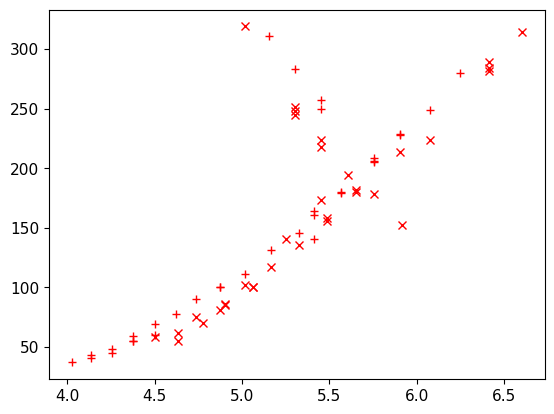

In [56]:
ind = np.where(eosdat_list[G24mcl['id']].T_liquid<8000)
plt.plot(eosdat_list[G24mcl['id']].rho_liquid[ind]+pbe_liquid_density_shift,eosdat_list[G24mcl['id']].P_liquid[ind],'+',color='red',label=G24mcl['lab']+ ' shift')
ind = np.where(eosdat_list[G24mcs['id']].T_solid<8000)        
plt.plot(eosdat_list[G24mcs['id']].rho_solid[ind]+pbe_liquid_density_shift,eosdat_list[G24mcs['id']].P_solid[ind],'x',color='red',label=G24mcs['lab']+' shift')
plt.show()